# m6A data cleaning — multiple datasets
## Goal
Clean the handout-style JSON and join optional labels by **transcript_id + transcript_position**. Each dataset is processed independently. Save all generated files outside the GitHub repository in `Team_Project/outputs/data_cleaning/<dataset_id>/<timestamp>/`.

Supports binary labels (including `0.0` / `1.0`), fractional labels, and no-label datasets. `gene_id` is optional; it is not present in the supplied JSON and is never invented. No train/test split, standardisation, imputation or class balancing is performed.

**Fraction policy:** preserve fractions by default. A binary conversion requires an explicit setting; neither `> 0` nor `>= 0.5` is scientifically established by the supplied files. A fraction is not automatically a probability that a site is modified.

**Source:** supplied project handout, original cleaning notebook, and three JSON lines in `Pasted text.txt`. The latter have 885, 1,069 and 1,933 reads, each with nine values. Full datasets are not included here.

## Setup
1. Save this notebook in your repository's `data_cleaning` folder and select your Python kernel.
2. Run the installation cell if needed, then restart the kernel.
3. Edit the configuration below. The notebook detects the enclosing `Team_Project` folder or accepts an explicit absolute path.
4. Use **Restart Kernel → Run All**. Default `MAX_LINES=None` reads the full JSON. For a format check, use 5000; a prefix is not a random sample.
5. New timestamped folders are created on each run. Raw inputs remain unchanged.


In [4]:
# Uncomment if needed, then restart the kernel.
# %pip install numpy pandas matplotlib ipykernel
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json, gzip, re, sys, platform, importlib.metadata, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print  # Allows execution in a plain Python environment too.
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
pd.set_option('display.max_columns', 12)


## 1. Paths and dataset settings
Your `dataset`, `outputs` and `DSA4262-datahelix` folders are siblings. Set input paths relative to `Team_Project`, or use absolute paths. Match the actual filenames on your machine.

Enable additional dataset entries only after editing their paths. Use `label_type='fraction'` when the dataset is defined as fractional—even if the first rows are all 1.0. There is no automatic inference from a small sample.

Fraction rules: `preserve` (default), `nonzero` (strictly > 0), or `threshold` (>= the specified threshold). Missing/invalid values never become zero. `threshold=0` is disallowed because it would classify zeros as positive.


In [11]:
def detect_project_root():
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / 'dataset').is_dir() and any(
            p.is_dir() and p.name.lower() == 'dsa4262-datahelix'
            for p in candidate.iterdir()
        ):
            return candidate
    raise FileNotFoundError('Set PROJECT_ROOT to the absolute path of Team_Project.')

# If detection fails, replace the next line with your actual path, e.g.
# PROJECT_ROOT = Path('/home/ubuntu/Team_Project')  # Ronin example only
# PROJECT_ROOT = Path(r'D:/your/folder/Team_Project')  # Windows example only
PROJECT_ROOT = detect_project_root()
OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'data_cleaning'  # Rename here if wanted.
MAX_LINES = None
MIN_VALID_READS = 1
REQUIRE_DRACH = True
EXPORT_CLEAN_READS = False  # True: also save valid read vectors for read-level/MIL models.

DATASETS = [
    dict(
        dataset_id='dataset0',
        json_path='dataset/data0/dataset0_json/dataset0.json',
        labels_path='dataset/data0/data.info.labelled',
        label_type='binary',
    ),
    dict(
        dataset_id='dataset1',
        json_path='dataset/data1/dataset1_json/dataset1.json',
        labels_path='dataset/data1/data.info',
        label_type='binary',
    ),
    dict(
        dataset_id='dataset2',
        json_path='dataset/data2/dataset2_json/dataset2.json',
        labels_path='dataset/data2/data.info',
        label_type='fraction',
        fraction_rule='nonzero',  # 0 -> 0; any positive fraction -> 1.
    ),
]

KEY = ['transcript_id', 'transcript_position']
SIGNALS = [f'{location}_{measure}' for location in ('minus1', 'center', 'plus1')
           for measure in ('dwell', 'signal_sd', 'signal_mean')]
STATS = ('mean', 'std', 'median', 'q25', 'q75')
FEATURES = [f'{name}_{stat}' for stat in STATS for name in SIGNALS]
MODEL_FEATURES = FEATURES + ['n_reads_valid', 'central_5mer']
print('Project:', PROJECT_ROOT)
print('Outputs:', OUTPUT_ROOT)


Project: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project
Outputs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\data_cleaning


## 2. Validate settings before processing
Outputs are required to be outside a Git repository. All input paths are checked before the first dataset is processed. Keep `dataset_id` unique: identical transcript/position keys from different datasets must not be treated as accidental duplicates.


In [12]:
def resolve_input(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else PROJECT_ROOT / p).resolve()

def validate_configuration():
    if not DATASETS:
        raise ValueError('Add at least one dataset.')
    if MIN_VALID_READS < 1 or (MAX_LINES is not None and MAX_LINES < 1):
        raise ValueError('Invalid read/line limits.')
    output = OUTPUT_ROOT.resolve()
    if any((p / '.git').exists() for p in (output, *output.parents)):
        raise ValueError('OUTPUT_ROOT must be outside the Git repository.')
    ids = [c['dataset_id'] for c in DATASETS]
    if len(set(ids)) != len(ids):
        raise ValueError('Dataset IDs must be unique.')
    for c in DATASETS:
        if not re.fullmatch(r'[A-Za-z0-9_-]+', c['dataset_id']):
            raise ValueError('Use letters, digits, underscores or hyphens in dataset_id.')
        if c['label_type'] not in ('binary', 'fraction', 'none'):
            raise ValueError('label_type must be binary, fraction or none.')
        paths = [resolve_input(c['json_path'])]
        if c['label_type'] != 'none':
            if not c.get('labels_path'):
                raise ValueError('Provide labels_path for labelled data.')
            paths.append(resolve_input(c['labels_path']))
        elif c.get('labels_path') is not None:
            raise ValueError('Set labels_path=None for unlabelled data.')
        rule = c.get('fraction_rule', 'preserve')
        if rule not in ('preserve', 'nonzero', 'threshold'):
            raise ValueError('Unknown fraction rule.')
        if c['label_type'] == 'fraction' and rule == 'threshold':
            t = c.get('fraction_threshold')
            if t is None or not np.isfinite(t) or not 0 < t <= 1:
                raise ValueError('Supply fraction_threshold in (0, 1].')
        for p in paths:
            if not p.is_file():
                raise FileNotFoundError(f'Edit the configuration: {p}')
            if output == p or output in p.parents:
                raise ValueError('Keep raw inputs outside OUTPUT_ROOT.')
    print('Configuration valid; mode:', 'FULL FILE' if MAX_LINES is None else f'FIRST {MAX_LINES} LINES')
validate_configuration()


Configuration valid; mode: FULL FILE


## 3. Read validation and feature extraction
Each read must have nine finite numeric values. Dwell times and signal SDs must be nonnegative. Identical vectors are counted but retained because distinct reads may share values. Extreme finite values are retained.

Across valid reads at each site, calculate 45 summaries: mean, population SD (`ddof=0`), median, 25th and 75th percentiles for each measurement. These are within-site summaries, not dataset-wide standardisation. They lose read-level structure; use the optional cleaned JSON when a model requires individual reads.

Malformed JSON, repeated JSON keys or an unexpected schema stop with a line number. Repeated site keys are quarantined in every occurrence, rather than merged.


In [13]:
def open_text(path):
    return gzip.open(path, 'rt', encoding='utf-8') if path.suffix == '.gz' else path.open(encoding='utf-8')

def unique_object(pairs):
    result = {}
    for k, v in pairs:
        if k in result:
            raise ValueError(f'Duplicate JSON key: {k!r}')
        result[k] = v
    return result

def read_matrix(reads):
    if not isinstance(reads, list):
        raise ValueError('Expected a list of reads')
    valid, reasons = [], Counter()
    for read in reads:
        if not isinstance(read, list) or len(read) != 9:
            reasons['wrong_length'] += 1; continue
        if any(isinstance(v, bool) or not isinstance(v, (int, float)) for v in read):
            reasons['nonnumeric'] += 1; continue
        a = np.asarray(read, dtype=float)
        if not np.isfinite(a).all():
            reasons['nonfinite'] += 1; continue
        if (a[[0, 1, 3, 4, 6, 7]] < 0).any():
            reasons['negative_dwell_or_sd'] += 1; continue
        valid.append(a)
    return np.asarray(valid, dtype=float).reshape(-1, 9), reasons

def parse_sites(path, max_lines=None):
    records, totals = [], Counter()
    with open_text(path) as handle:
        for line_no, line in enumerate(handle, 1):
            if max_lines is not None and line_no > max_lines: break
            totals['lines_scanned'] += 1
            if not line.strip():
                totals['blank_lines'] += 1; continue
            try:
                obj = json.loads(line, object_pairs_hook=unique_object)
                if not isinstance(obj, dict) or len(obj) != 1:
                    raise ValueError('Expected exactly one transcript per line')
                transcript, positions = next(iter(obj.items()))
                if not transcript.strip() or not isinstance(positions, dict) or len(positions) != 1:
                    raise ValueError('Expected one position and a nonempty transcript ID')
                pos, sequences = next(iter(positions.items()))
                if not re.fullmatch(r'\d+', pos):
                    raise ValueError('Position must be a nonnegative integer string')
                if not isinstance(sequences, dict) or len(sequences) != 1:
                    raise ValueError('Expected exactly one sequence per site')
                sequence, reads = next(iter(sequences.items()))
                a, reasons = read_matrix(reads)
                row = {'transcript_id': transcript, 'transcript_position': int(pos),
                       'sequence': sequence, 'central_5mer': sequence[1:6],
                       'source_line': line_no, 'n_reads_raw': len(reads),
                       'n_reads_valid': len(a), 'n_reads_removed': len(reads)-len(a),
                       'valid_sequence': bool(re.fullmatch('[ACGT]{7}', sequence)),
                       'is_drach': bool(re.fullmatch('[AGT][AG]AC[ACT]', sequence[1:6])),
                       'n_identical_vectors': len(a)-len(np.unique(a, axis=0))}
                for reason in ('wrong_length','nonnumeric','nonfinite','negative_dwell_or_sd'):
                    row['removed_'+reason] = reasons[reason]
                values = ([a.mean(0), a.std(0), np.median(a, axis=0),
                           np.quantile(a, .25, axis=0), np.quantile(a, .75, axis=0)]
                          if len(a) else [np.full(9, np.nan)]*5)
                row.update({f'{name}_{stat}': float(v)
                            for stat, arr in zip(STATS, values)
                            for name, v in zip(SIGNALS, arr)})
                records.append(row)
            except (ValueError, TypeError, OverflowError) as exc:
                raise ValueError(f'Cannot parse line {line_no}: {exc}') from exc
            if line_no % 10000 == 0: print(f'Parsed {line_no:,} lines')
    if not records: raise ValueError('No site records found')
    return pd.DataFrame(records), dict(totals)


## 4. Label handling
The minimum columns are transcript ID, position and label. Gene ID is optional. Extra columns are preserved with a `label_meta_` prefix so they cannot collide with signal features. `start` and `end` are not interpreted as genomic coordinates.

Numeric-equivalent duplicate rows are collapsed. Nonidentical rows sharing a site key are quarantined conservatively **before** fractional conversion. Missing or malformed labels are exported with a reason. No transcript suffix stripping or coordinate shifts are applied.

With `fraction_rule='preserve'`, **all** binary labels remain missing, even at fraction endpoints: no presence/absence ground truth is assumed. All valid fractions remain available in the annotated output.


In [14]:
def clean_labels(path, kind, rule='preserve', threshold=None):
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    required = set(KEY + ['label'])
    if not required.issubset(raw.columns):
        raise ValueError(f'Labels need {sorted(required)}; got {list(raw.columns)}')
    labels = raw[KEY].copy()
    labels['gene_id'] = raw['gene_id'] if 'gene_id' in raw else pd.NA
    labels['label_raw'] = raw['label']
    labels['source_label_row'] = np.arange(len(raw)) + 2
    for col in raw.columns:
        if col not in required | {'gene_id'}:
            labels['label_meta_' + col] = raw[col]
    value = pd.to_numeric(raw['label'], errors='coerce')
    valid_value = value.notna() & np.isfinite(value) & value.between(0, 1)
    if kind == 'binary':
        valid_value &= value.isin([0, 1])
    pos = raw['transcript_position']
    valid_pos = pos.str.fullmatch(r'\d+') & pos.map(
        lambda s: len(s) < 19 or (len(s) == 19 and s <= str(np.iinfo(np.int64).max)))
    valid_id = raw['transcript_id'].str.strip().ne('')
    reasons = pd.DataFrame({'invalid_position': ~valid_pos, 'missing_transcript_id': ~valid_id,
                            'invalid_label': ~valid_value})
    labels['label_issue'] = reasons.apply(lambda r: ';'.join(r.index[r]), axis=1)
    bad = labels.loc[labels.label_issue.ne('')].copy()
    labels = labels.loc[labels.label_issue.eq('')].drop(columns='label_issue').copy()
    labels['transcript_position'] = labels['transcript_position'].astype('int64')
    labels['label_value'] = value.loc[labels.index].astype(float)
    labels['gene_id'] = labels.gene_id.replace(r'^\s*$', pd.NA, regex=True)
    compare = [c for c in labels if c not in ('label_raw', 'source_label_row')]
    dup = labels.duplicated(compare)
    n_dup = int(dup.sum())
    labels = labels.loc[~dup].copy()
    conflict = labels.duplicated(KEY, keep=False)
    conflicts = labels.loc[conflict].copy()
    labels = labels.loc[~conflict].copy()
    labels['label'] = pd.Series(pd.NA, index=labels.index, dtype='Int8')
    labels['modification_fraction'] = np.nan
    if kind == 'binary':
        labels['label'] = labels.label_value.astype('Int8')
    else:
        labels['modification_fraction'] = labels.label_value
        if rule == 'nonzero':
            labels['label'] = labels.label_value.gt(0).astype('Int8')
        elif rule == 'threshold':
            labels['label'] = labels.label_value.ge(threshold).astype('Int8')
    labels['label_type'] = kind
    counts = dict(raw_label_rows=len(raw), invalid_label_rows=len(bad),
                  equivalent_duplicates_collapsed=n_dup, conflicting_label_rows=len(conflicts),
                  usable_label_sites=len(labels))
    return labels, bad, conflicts, counts


## 5. Process and export one dataset
Every run saves signal QC, invalid/conflicting labels, unmatched keys and a manifest. Read-count differences between the label file and JSON are reported, not automatically removed. They may need investigation.

Main files:
- `clean_signal_sites.csv.gz`: all QC-passing signal sites, including unlabelled sites.
- `clean_sites_with_labels.csv.gz`: matched, valid annotations, including preserved fractions.
- `clean_labeled_sites.csv.gz`: only rows with a valid **binary** `label`, compatible with the original binary-training interface. Empty in fraction-preserve mode.
- `clean_fraction_sites.csv.gz`: matched sites with preserved modification fractions.
- `feature_columns.json`: explicit predictor allowlist. Label and metadata columns are excluded.
- Optional `clean_reads.json.gz`: valid reads for all QC-passing sites, in the original JSON structure. Join targets by site key.


In [15]:
def safe_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return 'not available'

def export_clean_reads(source, destination, retained_keys):
    with open_text(source) as src, gzip.open(destination, 'wt', encoding='utf-8') as dst:
        for line_no, line in enumerate(src, 1):
            if MAX_LINES is not None and line_no > MAX_LINES:
                break
            if not line.strip():
                continue
            obj = json.loads(line, object_pairs_hook=unique_object)
            transcript, positions = next(iter(obj.items()))
            position, sequences = next(iter(positions.items()))
            if (transcript, int(position)) in retained_keys:
                sequence, reads = next(iter(sequences.items()))
                valid, _ = read_matrix(reads)
                dst.write(json.dumps({transcript: {position: {sequence: valid.tolist()}}}) + '\n')

def process_dataset(config):
    name, kind = config['dataset_id'], config['label_type']
    source = resolve_input(config['json_path'])
    label_path = resolve_input(config['labels_path']) if kind != 'none' else None
    rule = config.get('fraction_rule', 'preserve')
    threshold = config.get('fraction_threshold')
    run_dir = OUTPUT_ROOT / name / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir.mkdir(parents=True, exist_ok=False)
    print(f'Processing {name} → {run_dir}')
    sites, parse_counts = parse_sites(source, MAX_LINES)
    sites.insert(0, 'dataset_id', name)
    flags = pd.DataFrame({
        'duplicate_site': sites.duplicated(KEY, keep=False),
        'invalid_sequence': ~sites.valid_sequence,
        'non_drach': (~sites.is_drach) & REQUIRE_DRACH,
        'too_few_reads': sites.n_reads_valid < MIN_VALID_READS,
        'nonfinite_summary': ~np.isfinite(sites[FEATURES]).all(axis=1)})
    sites['qc_reason'] = flags.apply(lambda r: ';'.join(r.index[r]), axis=1)
    quarantined = sites.loc[sites.qc_reason.ne('')].copy()
    clean = sites.loc[sites.qc_reason.eq('')].copy()
    if kind != 'none':
        labels, bad, conflicts, label_counts = clean_labels(label_path, kind, rule, threshold)
    else:
        labels = pd.DataFrame({'transcript_id': pd.Series(dtype=str),
            'transcript_position': pd.Series(dtype='int64'), 'gene_id': pd.Series(dtype=str),
            'label_raw': pd.Series(dtype=str), 'label_value': pd.Series(dtype=float),
            'label': pd.Series(dtype='Int8'), 'modification_fraction': pd.Series(dtype=float),
            'label_type': pd.Series(dtype=str)})
        bad = pd.DataFrame(columns=KEY + ['label_raw', 'label_issue'])
        conflicts = pd.DataFrame(columns=KEY + ['label_raw'])
        label_counts = {}
    joined = clean.merge(labels, on=KEY, how='outer', validate='one_to_one', indicator=True)
    joined['dataset_id'] = name
    join_counts = joined['_merge'].value_counts().rename_axis('join_status').to_frame('sites')
    unmatched = joined.loc[joined['_merge'].ne('both'), ['dataset_id'] + KEY + ['_merge']]
    annotated = joined.loc[joined['_merge'].eq('both')].drop(columns='_merge').copy()
    annotated['transcript_position'] = annotated.transcript_position.astype('int64')
    annotated['label'] = annotated.label.astype('Int8')
    binary = annotated.loc[annotated.label.notna()].copy()
    fraction = annotated.loc[annotated.modification_fraction.notna()].copy()
    assert not clean.duplicated(KEY).any()
    assert np.isfinite(clean[FEATURES]).all().all()
    assert binary.label.isin([0, 1]).all()
    read_mismatches = pd.DataFrame(columns=KEY + ['n_reads_raw', 'label_meta_n_reads'])
    if 'label_meta_n_reads' in annotated:
        supplied = pd.to_numeric(annotated.label_meta_n_reads, errors='coerce')
        mismatch = supplied.isna() | ~np.isfinite(supplied) | supplied.ne(annotated.n_reads_raw)
        read_mismatches = annotated.loc[mismatch, KEY + ['n_reads_raw', 'label_meta_n_reads']]
    for table, filename in [
        (clean, 'clean_signal_sites.csv.gz'), (annotated, 'clean_sites_with_labels.csv.gz'),
        (binary, 'clean_labeled_sites.csv.gz'), (fraction, 'clean_fraction_sites.csv.gz'),
        (quarantined, 'quarantined_sites.csv.gz'), (bad, 'invalid_label_rows.csv'),
        (conflicts, 'conflicting_label_rows.csv'), (unmatched, 'unmatched_sites.csv.gz'),
        (read_mismatches, 'read_count_mismatches.csv')]:
        table.to_csv(run_dir / filename, index=False)
    join_counts.to_csv(run_dir / 'join_counts.csv')
    flags.sum().rename('sites').to_csv(run_dir / 'qc_reason_counts.csv')
    (run_dir / 'feature_columns.json').write_text(json.dumps(MODEL_FEATURES, indent=2))
    if EXPORT_CLEAN_READS:
        export_clean_reads(source, run_dir / 'clean_reads.json.gz',
                           set(clean[KEY].itertuples(index=False, name=None)))
    readiness = ('unlabelled signals only' if kind == 'none' else
                 'fractions preserved; no binary targets' if kind == 'fraction' and rule == 'preserve' else
                 'no binary rows survived' if binary.empty else
                 'binary labels available; ONE CLASS ONLY' if binary.label.nunique() < 2 else
                 'binary labels available')
    summary = dict(dataset_id=name, raw_sites=len(sites), signal_sites=len(clean),
        quarantined_sites=len(quarantined), annotated_sites=len(annotated),
        binary_sites=len(binary), fraction_sites=len(fraction),
        positive_sites=int(binary.label.sum()), read_count_mismatches=len(read_mismatches),
        status=readiness, run_dir=str(run_dir.resolve()))
    inputs = [source] + ([label_path] if label_path else [])
    manifest = dict(summary, config=config, max_lines=MAX_LINES, min_valid_reads=MIN_VALID_READS,
        require_drach=REQUIRE_DRACH, export_clean_reads=EXPORT_CLEAN_READS,
        parse_counts=parse_counts, label_counts=label_counts,
        removed_reads=int(sites.n_reads_removed.sum()),
        inputs=[dict(path=str(p), bytes=p.stat().st_size, mtime_ns=p.stat().st_mtime_ns) for p in inputs],
        python=sys.version, platform=platform.platform(),
        packages={p: safe_version(p) for p in ('numpy', 'pandas', 'matplotlib')},
        fraction_rule_applied=rule if kind == 'fraction' else None,
        fraction_threshold_applied=threshold if kind == 'fraction' and rule == 'threshold' else None,
        feature_columns=MODEL_FEATURES,
        notes='No split, scaling, imputation, clipping or resampling. Labels never used as predictors.')
    (run_dir / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
    return summary, clean, annotated, binary, fraction, join_counts


## 6. Run all configured datasets and review QC
Review the preview, join counts and exclusion reports. The expected ideal full-data join is dataset-dependent; do not assume mismatches are harmless. Prefix runs naturally leave many labels unmatched.

Plots and summary tables are saved to each run folder. Fraction sensitivity counts describe possible conversions; they do **not** select a scientifically valid threshold. Plots never change labels.


Processing dataset0 → D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\data_cleaning\dataset0\20261006T143139_734059Z
Parsed 10,000 lines
Parsed 20,000 lines
Parsed 30,000 lines
Parsed 40,000 lines
Parsed 50,000 lines
Parsed 60,000 lines
Parsed 70,000 lines
Parsed 80,000 lines
Parsed 90,000 lines
Parsed 100,000 lines
Parsed 110,000 lines
Parsed 120,000 lines


,dataset_id,raw_sites,signal_sites,quarantined_sites,annotated_sites,binary_sites,fraction_sites,positive_sites,read_count_mismatches,status,run_dir
0,dataset0,121838,121838,0,121838,121838,0,5475,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...


,dataset_id,transcript_id,transcript_position,sequence,central_5mer,source_line,...,label_raw,source_label_row,label_value,label,modification_fraction,label_type
0,dataset0,ENST00000000233,244,AAGACCA,AGACC,1,...,0,2,0.0,0,NaN,binary
1,dataset0,ENST00000000233,261,CAAACTG,AAACT,2,...,0,3,0.0,0,NaN,binary
2,dataset0,ENST00000000233,316,GAAACAG,AAACA,3,...,0,4,0.0,0,NaN,binary
3,dataset0,ENST00000000233,332,AGAACAT,GAACA,4,...,0,5,0.0,0,NaN,binary
4,dataset0,ENST00000000233,368,AGGACAA,GGACA,5,...,0,6,0.0,0,NaN,binary
5,dataset0,ENST00000000233,404,AGAACAC,GAACA,6,...,0,7,0.0,0,NaN,binary
6,dataset0,ENST00000000233,431,TGGACAG,GGACA,7,...,0,8,0.0,0,NaN,binary
7,dataset0,ENST00000000233,440,ATGACCG,TGACC,8,...,0,9,0.0,0,NaN,binary
8,dataset0,ENST00000000233,471,TGAACTC,GAACT,9,...,0,10,0.0,0,NaN,binary
9,dataset0,ENST00000000233,539,AGGACAT,GGACA,10,...,0,11,0.0,0,NaN,binary


,sites
join_status,
both,121838
left_only,0
right_only,0


Binary positive fraction: 4.49%


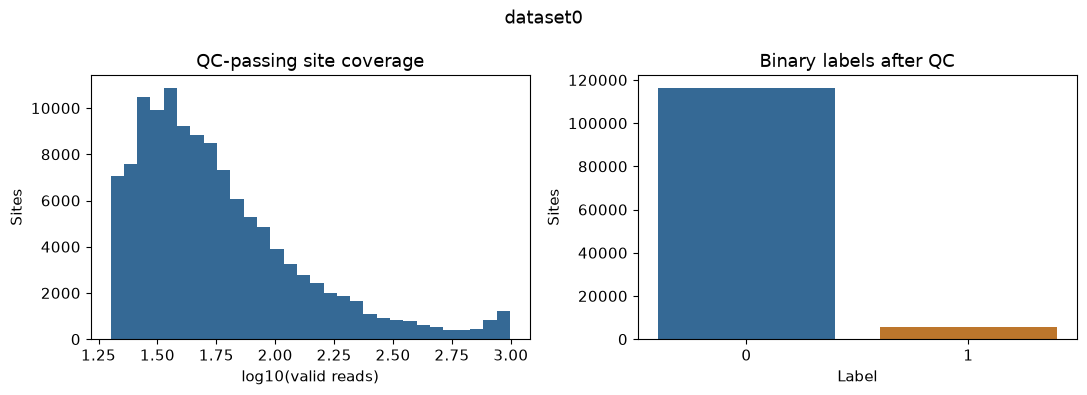

Processing dataset1 → D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\data_cleaning\dataset1\20261006T144017_412380Z
Parsed 10,000 lines
Parsed 20,000 lines
Parsed 30,000 lines
Parsed 40,000 lines
Parsed 50,000 lines
Parsed 60,000 lines
Parsed 70,000 lines
Parsed 80,000 lines
Parsed 90,000 lines


,dataset_id,raw_sites,signal_sites,quarantined_sites,annotated_sites,binary_sites,fraction_sites,positive_sites,read_count_mismatches,status,run_dir
0,dataset1,90810,90810,0,90810,90810,0,6593,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...


,dataset_id,transcript_id,transcript_position,sequence,central_5mer,source_line,...,label_meta_start,label_meta_end,label_value,label,modification_fraction,label_type
0,dataset1,ENST00000000233,244,AAGACCA,AGACC,1,...,0,9375,0.0,0,NaN,binary
1,dataset1,ENST00000000233,261,CAAACTG,AAACT,2,...,9375,18873,0.0,0,NaN,binary
2,dataset1,ENST00000000233,316,GAAACAG,AAACA,3,...,18873,28371,0.0,0,NaN,binary
3,dataset1,ENST00000000233,332,AGAACAT,GAACA,4,...,28371,38664,0.0,0,NaN,binary
4,dataset1,ENST00000000233,368,AGGACAA,GGACA,5,...,38664,48592,0.0,0,NaN,binary
5,dataset1,ENST00000000233,404,AGAACAC,GAACA,6,...,48592,58648,0.0,0,NaN,binary
6,dataset1,ENST00000000233,431,TGGACAG,GGACA,7,...,58648,68164,0.0,0,NaN,binary
7,dataset1,ENST00000000233,440,ATGACCG,TGACC,8,...,68164,78383,0.0,0,NaN,binary
8,dataset1,ENST00000000233,471,TGAACTC,GAACT,9,...,78383,89285,0.0,0,NaN,binary
9,dataset1,ENST00000000233,539,AGGACAT,GGACA,10,...,89285,98459,0.0,0,NaN,binary


,sites
join_status,
both,90810
left_only,0
right_only,0


Binary positive fraction: 7.26%


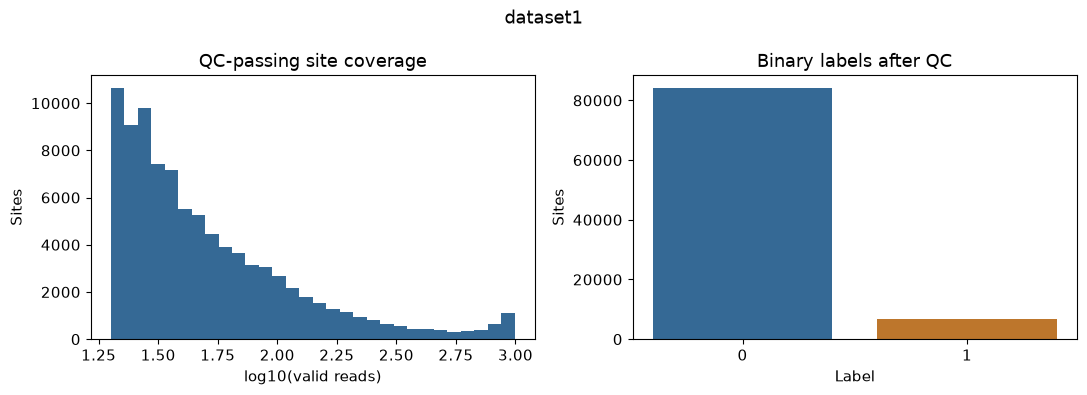

Processing dataset2 → D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\data_cleaning\dataset2\20261006T144639_349494Z


,dataset_id,raw_sites,signal_sites,quarantined_sites,annotated_sites,binary_sites,fraction_sites,positive_sites,read_count_mismatches,status,run_dir
0,dataset2,1323,1323,0,1323,1323,1323,1134,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...


,dataset_id,transcript_id,transcript_position,sequence,central_5mer,source_line,...,label_meta_start,label_meta_end,label_value,label,modification_fraction,label_type
0,dataset2,tx_id_0,0,AAAACCT,AAACC,1,...,0,49980,1.0,1,1.0,fraction
1,dataset2,tx_id_0,10,TGGACCC,GGACC,2,...,49980,110237,1.0,1,1.0,fraction
2,dataset2,tx_id_0,20,GGGACTA,GGACT,3,...,110237,219323,1.0,1,1.0,fraction
3,dataset2,tx_id_0,30,TGGACCA,GGACC,4,...,219323,257931,1.0,1,1.0,fraction
4,dataset2,tx_id_0,40,TAGACTA,AGACT,5,...,257931,363218,1.0,1,1.0,fraction
5,dataset2,tx_id_0,50,TTAACTA,TAACT,6,...,363218,471111,1.0,1,1.0,fraction
6,dataset2,tx_id_0,60,CAAACAA,AAACA,7,...,471111,536740,1.0,1,1.0,fraction
7,dataset2,tx_id_0,70,CTAACAC,TAACA,8,...,536740,613824,1.0,1,1.0,fraction
8,dataset2,tx_id_0,80,GTAACAT,TAACA,9,...,613824,699618,1.0,1,1.0,fraction
9,dataset2,tx_id_0,90,CGAACAA,GAACA,10,...,699618,804494,1.0,1,1.0,fraction


,sites
join_status,
both,1323
left_only,0
right_only,0


Binary positive fraction: 85.71%


,rule,positive_sites,negative_sites,positive_fraction
0,> 0,1134,189,0.857143
1,>= 0.01,1134,189,0.857143
2,>= 0.05,1134,189,0.857143
3,>= 0.1,1134,189,0.857143
4,>= 0.2,1134,189,0.857143
5,>= 0.5,945,378,0.714286


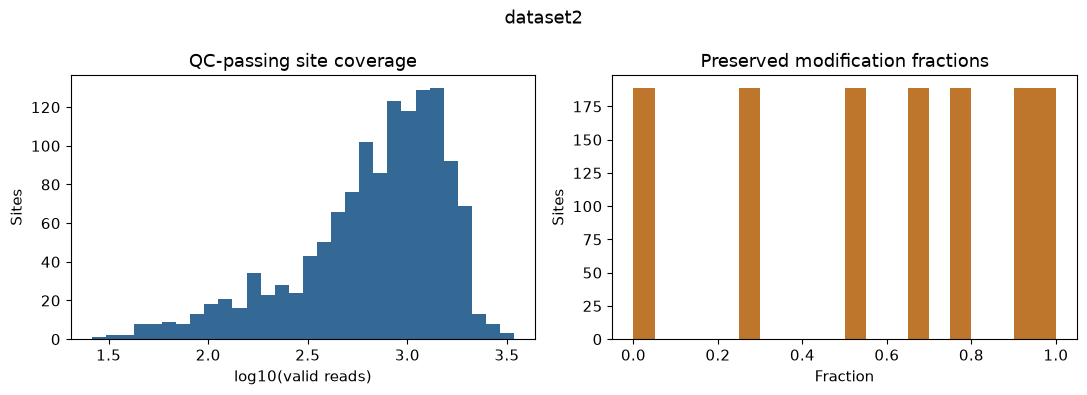

,dataset_id,raw_sites,signal_sites,quarantined_sites,annotated_sites,binary_sites,fraction_sites,positive_sites,read_count_mismatches,status,run_dir
0,dataset0,121838,121838,0,121838,121838,0,5475,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...
1,dataset1,90810,90810,0,90810,90810,0,6593,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...
2,dataset2,1323,1323,0,1323,1323,1323,1134,0,binary labels available,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...


Completed. Exact output paths appear in run_dir above.


In [16]:
def report_dataset(summary, clean, annotated, binary, fraction, joins):
    folder = Path(summary['run_dir'])
    display(pd.DataFrame([summary]))
    display(annotated.head(10) if len(annotated) else clean.head(10))
    display(joins)
    counts = binary.label.value_counts().reindex([0, 1], fill_value=0)
    counts.rename('sites').to_csv(folder / 'binary_class_counts.csv')
    if len(binary):
        print(f'Binary positive fraction: {binary.label.mean():.2%}')
    if len(fraction):
        values = fraction.modification_fraction
        sensitivity = []
        for caption, mask in [('> 0', values.gt(0))] + [
            (f'>= {t}', values.ge(t)) for t in (.01, .05, .1, .2, .5)]:
            sensitivity.append(dict(rule=caption, positive_sites=int(mask.sum()),
                                    negative_sites=int((~mask).sum()), positive_fraction=float(mask.mean())))
        table = pd.DataFrame(sensitivity)
        display(table)
        table.to_csv(folder / 'fraction_threshold_sensitivity.csv', index=False)
        values.describe().to_csv(folder / 'fraction_summary.csv')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    if len(clean):
        axes[0].hist(np.log10(clean.n_reads_valid), bins=30, color='#356995')
    axes[0].set(title='QC-passing site coverage', xlabel='log10(valid reads)', ylabel='Sites')
    if len(fraction):
        axes[1].hist(fraction.modification_fraction, bins=np.linspace(0, 1, 21), color='#bd762c')
        axes[1].set(title='Preserved modification fractions', xlabel='Fraction', ylabel='Sites')
    elif len(binary):
        axes[1].bar(['0', '1'], counts.values, color=['#356995', '#bd762c'])
        axes[1].set(title='Binary labels after QC', xlabel='Label', ylabel='Sites')
    else:
        axes[1].text(.5, .5, 'No binary or fractional labels available', ha='center', wrap=True)
        axes[1].set_axis_off()
    fig.suptitle(summary['dataset_id'])
    fig.tight_layout()
    fig.savefig(folder / 'qc_overview.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

run_summaries = []
for config in DATASETS:
    result = process_dataset(config)
    report_dataset(*result)
    run_summaries.append(result[0])
    del result
    gc.collect()  # Process one dataset at a time instead of retaining all dataframes.
run_summary = pd.DataFrame(run_summaries)
display(run_summary)
print('Completed. Exact output paths appear in run_dir above.')


## 7. Use the outputs for training
For binary models, load `clean_labeled_sites.csv.gz` and the predictor allowlist from the **same run folder**. `central_5mer` is categorical and requires encoding in your training pipeline. Fit encoding, scaling, resampling and any data-learned transformations on each cross-validation training fold only.

Never use `label_raw`, `label_value`, `modification_fraction`, identifiers, `label_meta_*` or source-row information as predictors. Preserving a fraction does not make it compatible with binary ROC/PR evaluation.

Example (not executed automatically):
```python
run_dir = Path(run_summaries[0]['run_dir'])
df = pd.read_csv(run_dir / 'clean_labeled_sites.csv.gz')
feature_columns = json.loads((run_dir / 'feature_columns.json').read_text())
if df.empty:
    raise ValueError('No binary targets: inspect label policy and QC.')
if df['label'].nunique() < 2:
    raise ValueError('Need both classes for binary model training/evaluation.')
X = df[feature_columns].copy()
y = df['label'].astype('int8')
```
For fractional analysis use `clean_fraction_sites.csv.gz`. Predicting fractions requires an intentionally designed model objective and evaluation rather than silently passing them to a classifier.

For an LSTM, inspect the training notebook's expected tensor layout: these CSVs contain site summaries, not a read sequence. If it expects read vectors, set `EXPORT_CLEAN_READS=True` and use the saved JSON. The cleaning notebook cannot establish the appropriate biological sequence axis for your model.

For pooled datasets retain `dataset_id` as provenance, not a default predictor. IDs reused across datasets may refer to unrelated sites, while shared biological sites can require joint grouping during validation. Missing gene IDs cannot support gene-disjoint folds without a mapping.

## Checks and handoff
- Real data must be run locally with correct paths; the delivered notebook has no fabricated full-data results.
- Review counts, unmatched keys and quarantine files before training; a completed run does not by itself establish data quality.
- This notebook does not move or unstage old outputs already inside your repository. Move them separately and ensure your notebook's saved cell outputs do not contain data you wish to keep out of GitHub (clear outputs before committing).
- For prediction submissions, the handout requires original site keys. A downstream prediction script needs a deliberate fallback for quarantined sites; this cleaning output alone is not a complete submission.
- Document AI assistance and verified corrections as required by your handout.


**Validation performed:** notebook schema and Python syntax checked; cells executed in order with temporary paths using the three supplied JSON records and synthetic binary/fractional labels. Checked preservation, explicit nonzero/threshold conversion, missing genes, invalid labels, duplicate/conflict handling, unlabelled input and cleaned-read export. Full-data execution remains your local validation step.
